In [4]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

np.random.seed(7); tf.random.set_seed(7)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [6]:
num_notes       = 40    # vocabulary size (given)
sequence_length = 25     # notes per melody (given)
num_sequences   = 1200   # number of melodies (given)

data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))  # (given)
print("Data Shape:",data.shape)

# Q1a) input = all notes except the LAST;  target = all notes except the FIRST
x_train = data[:, :-1]   # TODO (Q1a): data[:, :-1]
y_train =  data[:, 1:]   # TODO (Q1a): data[:, 1:]

# Q1b) one-hot encode both to shape (samples, 29, 50)
NUM_CLASSES = 40   # TODO (Q1b): how many distinct notes?
x_train = to_categorical(x_train, num_classes=NUM_CLASSES)
y_train = to_categorical(y_train, num_classes=NUM_CLASSES)

print("x_train:", x_train.shape, " y_train:", y_train.shape)   # expect (1000, 29, 50) each

Data Shape: (1200, 25)
x_train: (1200, 24, 40)  y_train: (1200, 24, 40)


Q. Why is the target the input shifted by one? What task does that set up?

**Answer:** Shifting the target by one sets up the task of **next-step prediction** (autoregressive forecasting), where at each time step $t$, the model learns to predict the next note $x_{t+1}$ using the historical context up to step $t$.

In [5]:
model = models.Sequential()
model.add(layers.Input(shape=(sequence_length-1, num_notes)))        # (29, 50)  (given)

# Q2a) first Bidirectional LSTM: 128 units, return a sequence
model.add(layers.Bidirectional(layers.LSTM(100, return_sequences=True)))  # TODO (Q2a)

# Q2b) second Bidirectional LSTM: same settings
model.add(layers.Bidirectional(layers.LSTM(100, return_sequences=True)))   # TODO (Q2b): another Bidirectional(LSTM(128, return_sequences=True))

# Q2c) TimeDistributed Dense output: one softmax classifier per step
model.add(layers.TimeDistributed(layers.Dense(40, activation='softmax')))  # TODO (Q2c)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 24, 200)        │       112,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 24, 200)        │       240,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 24, 40)         │         8,040 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,640 (1.38 MB)

 Trainable params: 361,640 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

Q. Each LSTM has 100 units, yet each Bidirectional layer outputs 200 features per step —
why? And what does TimeDistributed do with the Dense layer?

**Answer:**
* **200 features:** A Bidirectional layer runs two LSTMs (100 units forward, 100 units backward) and concatenates their outputs, doubling the feature size.
* **TimeDistributed:** It applies the same Dense layer independently to each individual time step of the sequence, preserving the temporal dimension.

In [7]:
# Q3a) compile for multi-class, one-hot targets
model.compile(optimizer=Adam(learning_rate=0.001),   # TODO (Q3a): 0.001
              loss='categorical_crossentropy',                             # TODO (Q3a): 'categorical_crossentropy'
              metrics=['accuracy'])

# Q3b) train with a 20% validation split
history = model.fit(x_train, y_train,
                    epochs=15,            # TODO (Q3b): 20
                    batch_size=64,        # TODO (Q3b): 64
                    validation_split=0.2)  # TODO (Q3b): 0.2

Epoch 1/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 214ms/step - accuracy: 0.1199 - loss: 3.6589 - val_accuracy: 0.1922 - val_loss: 3.6178
Epoch 2/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 268ms/step - accuracy: 0.1563 - loss: 3.5377 - val_accuracy: 0.1220 - val_loss: 3.4078
Epoch 3/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 153ms/step - accuracy: 0.1402 - loss: 3.2635 - val_accuracy: 0.1628 - val_loss: 3.1354
Epoch 4/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 158ms/step - accuracy: 0.1842 - loss: 2.9712 - val_accuracy: 0.2033 - val_loss: 2.8333
Epoch 5/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 304ms/step - accuracy: 0.2425 - loss: 2.6204 - val_accuracy: 0.2747 - val_loss: 2.4700
Epoch 6/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 270ms/step - accuracy: 0.3207 - loss: 2.2363 - val_accuracy: 0.3587 - val_loss: 2.0755
Epoch 7/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 146ms/step - accuracy: 0.4055 - loss: 1.8629 - val_accuracy: 0.4410 - val_loss: 1.7277
Epoch 8/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 157ms/step - accuracy: 0.5059 - loss: 1.5273 - val_accuracy: 0.

Q. Why is categorical_crossentropy the correct loss here (think about the one-hot
targets)?

**Answer:** Categorical crossentropy is designed for multi-class classification where target labels are provided as probability distributions (like one-hot vectors), measuring the distance between the predicted softmax probabilities and the true one-hot classes.

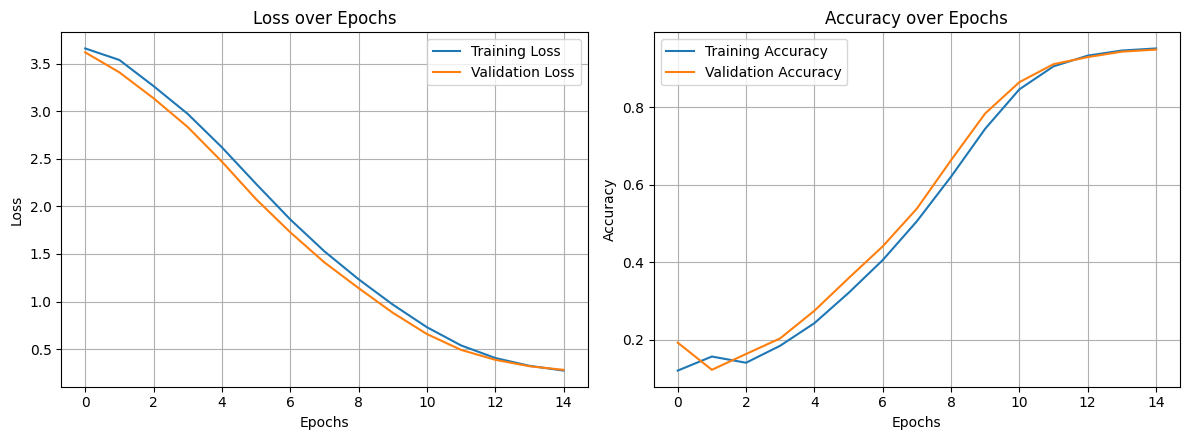

In [8]:
plt.figure(figsize=(12,4.5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'],     label='Training Loss')
plt.plot(history.history['val_loss'],       label='Validation Loss')   # TODO (Q4a): val loss key
plt.title('Loss over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'],       label='Validation Accuracy')  # TODO (Q4b): val acc key
plt.title('Accuracy over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid()

plt.tight_layout(); plt.show()

Q. Do the training and validation curves stay close together? What would a big gap
between them have told you?

**Answer:** Yes, they stay very close together. A big gap (high training performance but poor validation performance) would indicate **overfitting**, meaning the model has memorized the training patterns and failed to generalize.

In [9]:
def generate_music(model, start_sequence, num_generated_notes=40):
    generated = []
    current_sequence = start_sequence
    for _ in range(num_generated_notes):
        pred = model.predict(current_sequence, verbose=0)      # (1, 29, 50)

        # Q5a) pick the most likely note at the LAST time step
        next_note =  np.argmax(pred[:, -1, :], axis=-1)   # TODO (Q5a): np.argmax(pred[:, -1, :], axis=-1)
        generated.append(int(next_note[0]))

        # Q5b) slide the window: drop the first step, append the new note (one-hot)
        oh = to_categorical(next_note, num_classes=num_notes).reshape(1, 1, num_notes)
        current_sequence =np.concatenate([current_sequence[:, 1:, :], oh], axis=1)   # TODO (Q5b): np.concatenate([current_sequence[:, 1:, :], oh], axis=1)
    return generated

# seed window (given)
start = np.random.randint(0, num_notes, size=(1, sequence_length-1))
start = to_categorical(start, num_classes=num_notes)

generated_music = generate_music(model, start, num_generated_notes=50)
print("Generated:", generated_music)

Generated: [26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26, 26]


Q. At each step, which time-step’s prediction do you keep, and how do you update the
input window for the next step?

**Answer:** We keep only the prediction at the **last time step** of the sequence. We then slide the input window by discarding the oldest note (first index) and appending this newly predicted note to the end of the sequence.

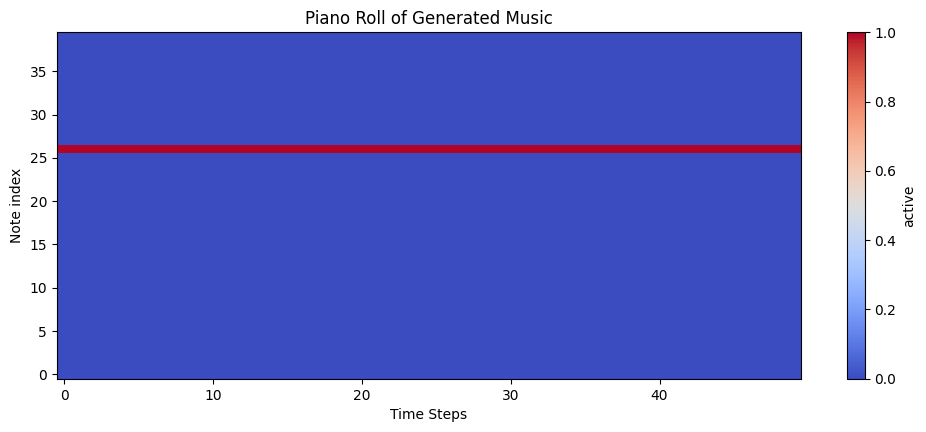

In [10]:
piano_roll = np.zeros((num_notes, len(generated_music)))
for t, note in enumerate(generated_music):
    piano_roll[note, t] = 1   # TODO (Q6): which row is the active note at time t?

plt.figure(figsize=(12,4.5))
plt.imshow(piano_roll, aspect='auto', cmap='coolwarm', origin='lower', interpolation='nearest')
plt.colorbar(label='active'); plt.title('Piano Roll of Generated Music')
plt.xlabel('Time Steps'); plt.ylabel('Note index'); plt.show()

Q. What does one column of the piano-roll represent, and why is exactly one cell active in
each column?

**Answer:** One column represents a single point in time. Exactly one cell is active because each time step can play only one note at a time, corresponding to the argmax (highest probability) class selection.

In [11]:
import numpy as np
from IPython.display import Audio
audio = np.concatenate([np.sin(2 * np.pi * (440.0 * (2.0 ** (((48 + n) - 69.0) / 12.0))) * np.linspace(0, 0.25, 2000, False)) for n in generated_music])
Audio(audio, rate=8000)

A one - line explanation naming " label leakage ": the backward direction already sees the next note , so the model copies it instead of learning music .

Label leakage occurs in bidirectional RNNs because the backward pass has access to the future sequence, allowing the model to simply copy the next note during training instead of learning to predict it.
